# Student Pass/Fail Prediction with Logistic Regression

This practical creates a reproducible student marks dataset, trains a logistic regression model, predicts raw datapoints, and compares pass-mark thresholds of **5** and **7**.

- A mark of 5 or more is treated as the original pass criterion.
- The threshold of 7 is tested as a stricter alternative.
- The model probability cutoff remains 0.5; only the raw-mark decision threshold changes.

## 1. Import libraries and create the training dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

np.random.seed(42)

# One raw datapoint is a student's score out of 10.
marks = np.array([1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5,
                  4.8, 5.0, 5.2, 5.5, 6.0, 6.5, 7.0, 7.5,
                  8.0, 8.5, 9.0, 9.5])

# Training labels: 1 = pass and 0 = fail, using the standard cutoff of 5.
passed = (marks >= 5).astype(int)
students = pd.DataFrame({"marks": marks, "result": passed})
students["result_label"] = students["result"].map({0: "Fail", 1: "Pass"})
students

,marks,result,result_label
0,1.0,0,Fail
1,1.5,0,Fail
2,2.0,0,Fail
3,2.5,0,Fail
4,3.0,0,Fail
5,3.5,0,Fail
6,4.0,0,Fail
7,4.5,0,Fail
8,4.8,0,Fail
9,5.0,1,Pass


## 2. Train logistic regression and predict raw datapoints

The model learns the probability that a student passes from the student's mark. The two requested raw datapoints, 5 and 7, are also passed through the trained model.

In [2]:
X = students[["marks"]]
y = students["result"]

model = LogisticRegression(solver="lbfgs")
model.fit(X, y)

raw_datapoints = pd.DataFrame({"marks": [5.0, 7.0]})
raw_probabilities = model.predict_proba(raw_datapoints)[:, 1]
raw_predictions = (raw_probabilities >= 0.5).astype(int)
raw_predictions_table = pd.DataFrame({
    "raw_mark": raw_datapoints["marks"],
    "predicted_pass_probability": raw_probabilities.round(4),
    "predicted_result": np.where(raw_predictions == 1, "Pass", "Fail")
})
raw_predictions_table

,raw_mark,predicted_pass_probability,predicted_result
0,5.0,0.5698,Pass
1,7.0,0.9663,Pass


## 3. Compare thresholds 5 and 7

Here, the logistic regression probabilities are unchanged. We compare the final decision made from the raw mark using two different pass thresholds.

In [3]:
thresholds = [5, 7]
comparison_rows = []

for threshold in thresholds:
    threshold_predictions = (students["marks"] >= threshold).astype(int)
    comparison_rows.append({
        "threshold": threshold,
        "pass_count": int(threshold_predictions.sum()),
        "fail_count": int((1 - threshold_predictions).sum()),
        "accuracy_against_training_labels": accuracy_score(y, threshold_predictions)
    })
threshold_comparison = pd.DataFrame(comparison_rows)
threshold_comparison

,threshold,pass_count,fail_count,accuracy_against_training_labels
0,5,11,9,1.00
1,7,6,14,0.75


In [4]:
comparison_table = students[["marks", "result_label"]].copy()
comparison_table["threshold_5_result"] = np.where(comparison_table["marks"] >= 5, "Pass", "Fail")
comparison_table["threshold_7_result"] = np.where(comparison_table["marks"] >= 7, "Pass", "Fail")
comparison_table

,marks,result_label,threshold_5_result,threshold_7_result
0,1.0,Fail,Fail,Fail
1,1.5,Fail,Fail,Fail
2,2.0,Fail,Fail,Fail
3,2.5,Fail,Fail,Fail
4,3.0,Fail,Fail,Fail
5,3.5,Fail,Fail,Fail
6,4.0,Fail,Fail,Fail
7,4.5,Fail,Fail,Fail
8,4.8,Fail,Fail,Fail
9,5.0,Pass,Pass,Fail


## 4. Visualize the logistic curve and threshold decisions

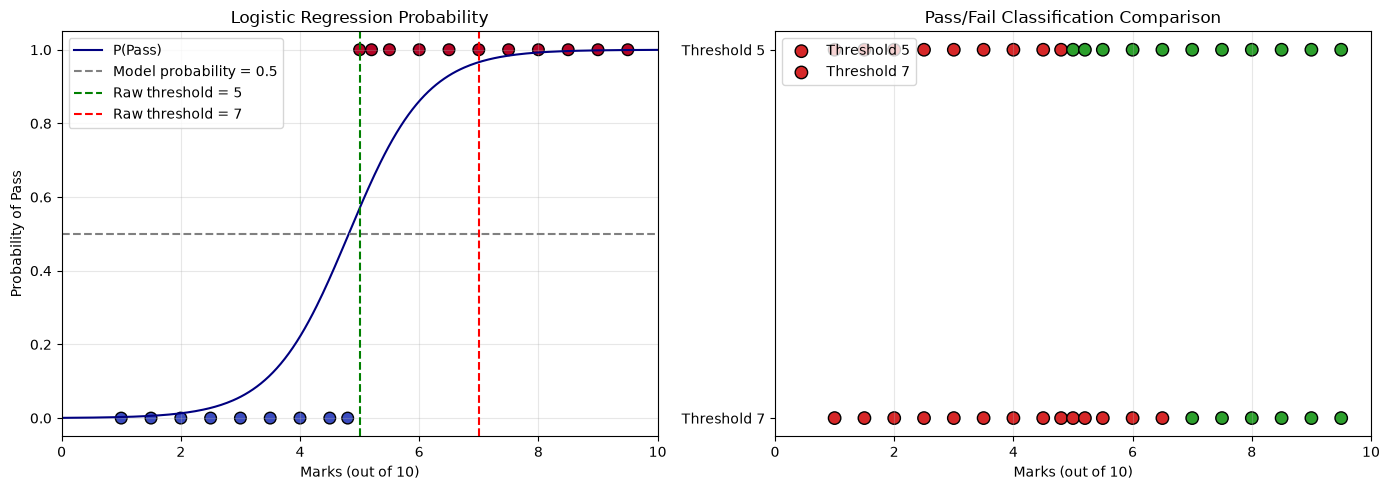

In [5]:
marks_grid = pd.DataFrame({"marks": np.linspace(0, 10, 300)})
probability_grid = model.predict_proba(marks_grid)[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Logistic-regression probability curve.
axes[0].plot(marks_grid["marks"], probability_grid, color="navy", label="P(Pass)")
axes[0].scatter(marks, passed, c=passed, cmap="coolwarm", edgecolor="black", s=70)
axes[0].axhline(0.5, color="gray", linestyle="--", label="Model probability = 0.5")
axes[0].axvline(5, color="green", linestyle="--", label="Raw threshold = 5")
axes[0].axvline(7, color="red", linestyle="--", label="Raw threshold = 7")
axes[0].set(title="Logistic Regression Probability", xlabel="Marks (out of 10)", ylabel="Probability of Pass")
axes[0].set_xlim(0, 10)
axes[0].set_ylim(-0.05, 1.05)
axes[0].legend()
axes[0].grid(alpha=0.3)
    # Side-by-side raw-mark classifications.
colors_5 = np.where(marks >= 5, "tab:green", "tab:red")
colors_7 = np.where(marks >= 7, "tab:green", "tab:red")
axes[1].scatter(marks, np.ones_like(marks), c=colors_5, edgecolor="black", s=80, label="Threshold 5")
axes[1].scatter(marks, np.zeros_like(marks), c=colors_7, edgecolor="black", s=80, label="Threshold 7")
axes[1].set_yticks([0, 1], ["Threshold 7", "Threshold 5"])
axes[1].set(title="Pass/Fail Classification Comparison", xlabel="Marks (out of 10)")
axes[1].set_xlim(0, 10)
axes[1].grid(axis="x", alpha=0.3)
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5. Confusion matrices and conclusion

Threshold 5 matches the labels used to create the training data. Threshold 7 is stricter: students scoring 5.0 through 6.5 change from Pass to Fail, so the number of predicted passes decreases.

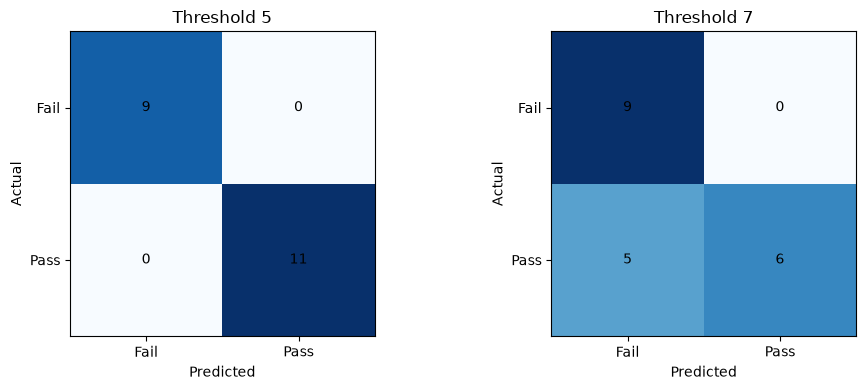

Classification report for threshold 5:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         9
        Pass       1.00      1.00      1.00        11

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20

Classification report for threshold 7:
              precision    recall  f1-score   support

        Fail       0.64      1.00      0.78         9
        Pass       1.00      0.55      0.71        11

    accuracy                           0.75        20
   macro avg       0.82      0.77      0.74        20
weighted avg       0.84      0.75      0.74        20



In [6]:
predictions_5 = (students["marks"] >= 5).astype(int)
predictions_7 = (students["marks"] >= 7).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, threshold, predictions in zip(axes, [5, 7], [predictions_5, predictions_7]):
        matrix = confusion_matrix(y, predictions)
        image = axis.imshow(matrix, cmap="Blues")
        axis.set(title=f"Threshold {threshold}", xlabel="Predicted", ylabel="Actual")
        axis.set_xticks([0, 1], ["Fail", "Pass"])
        axis.set_yticks([0, 1], ["Fail", "Pass"])
        for (row, column), value in np.ndenumerate(matrix):
            axis.text(column, row, value, ha="center", va="center", color="black")
plt.tight_layout()
plt.show()
print("Classification report for threshold 5:")
print(classification_report(y, predictions_5, target_names=["Fail", "Pass"], zero_division=0))
print("Classification report for threshold 7:")
print(classification_report(y, predictions_7, target_names=["Fail", "Pass"], zero_division=0))